# ORI 2026 - EKSPERIMENT 1: PREDVIĐANJE CENA (V3 — poboljšano + Confusion Matrix)
## 1-1, 1-2, 1-3 (a/b/c podslučajevi) — sve regresija

Ovaj notebook:
- ✅ Učitava CSV fajlove (Date, Price, Open, High, Low, Vol.)
- ✅ Izveštaj o nedostajućim vrednostima po paru
- ✅ Indikatori pomoću `ta` paketa (SMA, EMA, ROC, RSI, MACD, STD, ATR)
- ✅ Eksperiment 1-1: cene / indikatori / cene+indikatori → cena(t+1,t+5,t+10)
- ✅ Eksperiment 1-2: + ROC od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)
- ✅ Eksperiment 1-3: + ROC i SMA od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)
- ✅ MLP regresor za svaku kombinaciju (par × podslučaj × horizont)
- ✅ Print svih rezultata + Excel tabela na kraju
- 🆕 **V3: MAPE metrika, Direction Accuracy, Confusion Matrix smera kretanja**

### 🆕 Izmene u V3:
1. **Dublja MLP arhitektura** `(64, 32, 16)` umesto `(32, 16)` — bolja aproksimacija kompleksnih zavisnosti.
2. **MAPE metrika** (Mean Absolute Percentage Error) — lakše porediti greške između valutnih parova sa različitim opsezima cena.
3. **Direction Accuracy** — procenat pravilno predviđenih smerova kretanja cene.
4. **Confusion Matrix** — binarizacija smera (UP/DOWN) + TP/TN/FP/FN + Accuracy/Precision/Recall/F1 po kombinaciji.
5. **Vizuelni grid confusion matrica** — po paru × horizontu za reprezentativan podslučaj.
6. Svi rezultati sačuvani u dva Excel fajla: `Experiment1_Results.xlsx` i `Experiment1_ConfusionMatrix.xlsx`.


In [2]:
import pandas as pd
import numpy as np
import os
import glob
import warnings
from math import sqrt
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from matplotlib.patches import FancyArrowPatch,FancyBboxPatch

warnings.filterwarnings('ignore')

possible_dirs = [".", "data", "./data", "../data"]
INPUT_DIR = ""

for dir_path in possible_dirs:
    if os.path.exists(dir_path):
        csv_files = glob.glob(os.path.join(dir_path, "*_Data.csv"))
        if csv_files and len(csv_files) >= 5:
            INPUT_DIR = dir_path
            break

print(f"✓ CSV fajlovi pronađeni u: {INPUT_DIR}")
print(f"✓ Sve biblioteke učitane!")

✓ CSV fajlovi pronađeni u: data
✓ Sve biblioteke učitane!


## 📋 FAZA 1: Priprema podataka

In [3]:

## 📋 FAZA 1: Priprema podataka
def load_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    return df


def clean_numeric_column(series):
    """Konvertuje string kolonu (zarezi/procenti/K,M,B sufiksi) u numeričku."""
    s = series.astype(str).str.replace(",", "", regex=False)
    s = s.str.replace("%", "", regex=False)

    def parse_suffix(val):
        if not isinstance(val, str):
            return np.nan if pd.isna(val) else float(val)
        val = val.strip()
        if val in ("", "nan", "None", "-"):
            return np.nan
        multiplier = 1
        if val.endswith("K"):
            multiplier, val = 1_000, val[:-1]
        elif val.endswith("M"):
            multiplier, val = 1_000_000, val[:-1]
        elif val.endswith("B"):
            multiplier, val = 1_000_000_000, val[:-1]
        try:
            return float(val) * multiplier
        except ValueError:
            return np.nan

    return s.apply(parse_suffix)


csv_files = sorted(glob.glob(os.path.join(INPUT_DIR, "*_Data.csv")))
print(f"Pronađeno {len(csv_files)} CSV fajlova:\n")

all_data = []
missing_report = []

for path in csv_files:
    pair_name = os.path.basename(path).replace("_Data.csv", "")
    df_raw = load_csv(path)

    df_raw["Date"] = pd.to_datetime(df_raw["Date"], format="%m/%d/%Y", errors="coerce")

    numeric_cols = [c for c in ["Price", "Open", "High", "Low", "Change %"] if c in df_raw.columns]
    for col in numeric_cols:
        df_raw[col] = clean_numeric_column(df_raw[col])

    total_rows = len(df_raw)
    cols_to_check = ["Date"] + numeric_cols
    missing_counts = df_raw[cols_to_check].isna().sum()
    missing_pct = (missing_counts / total_rows * 100).round(2)

    report_row = {"Pair": pair_name, "Total_Rows": total_rows}
    for col in cols_to_check:
        report_row[f"{col}_missing_%"] = missing_pct[col]
    missing_report.append(report_row)

    keep_cols = ["Date"] + numeric_cols
    df = df_raw[keep_cols].dropna(subset=["Date", "Price"])
    df["Pair"] = pair_name

    all_data.append(df)
    print(f"  ✓ {pair_name:10s}: {len(df)} redova (od {total_rows} ukupno)")

# --- Ukloni redove iz USDCNY čiji datum se ne javlja kod NIJEDNOG drugog para ---
# (npr. praznik specifičan za CNY kad ostali parovi ne trguju)
other_dates = set()
for df in all_data:
    if df["Pair"].iloc[0] != "USDCNY":
        other_dates.update(df["Date"])

for i, df in enumerate(all_data):
    if df["Pair"].iloc[0] == "USDCNY":
        before = len(df)
        all_data[i] = df[df["Date"].isin(other_dates)]
        removed = before - len(all_data[i])
        if removed > 0:
            print(f"\n  ⚠ USDCNY: uklonjeno {removed} redova sa datumima koji se ne javljaju kod ostalih parova "
                  f"({before} → {len(all_data[i])})")

currency_all = pd.concat(all_data, ignore_index=True)
currency_all = currency_all.sort_values(["Pair", "Date"]).reset_index(drop=True)

print(f"\n✓ Ukupno: {len(currency_all)} redova za {currency_all['Pair'].nunique()} parova")

Pronađeno 6 CSV fajlova:

  ✓ EURUSD    : 2610 redova (od 2610 ukupno)
  ✓ USDCAD    : 2610 redova (od 2610 ukupno)
  ✓ USDCHF    : 2610 redova (od 2610 ukupno)
  ✓ USDCNY    : 2611 redova (od 2611 ukupno)
  ✓ USDGBP    : 2610 redova (od 2610 ukupno)
  ✓ USDJPY    : 2610 redova (od 2610 ukupno)

  ⚠ USDCNY: uklonjeno 1 redova sa datumima koji se ne javljaju kod ostalih parova (2611 → 2610)

✓ Ukupno: 15660 redova za 6 parova


### 📊 Izveštaj o nedostajućim vrednostima po valutnom paru

In [4]:
missing_df = pd.DataFrame(missing_report)
print("="*80)
print("UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)")
print("="*80 + "\n")
print(missing_df.to_string(index=False))

UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)

  Pair  Total_Rows  Date_missing_%  Price_missing_%  Open_missing_%  High_missing_%  Low_missing_%  Change %_missing_%
EURUSD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCAD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCHF        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCNY        2611             0.0              0.0             0.0             0.0            0.0                 0.0
USDGBP        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDJPY        2610             0.0              0.0             0.0             0.0            0.0                 0.0


## 🔧 FAZA 2: Inženjering indikatora (paket `ta`)

In [5]:
from ta.trend import SMAIndicator, EMAIndicator, MACD, CCIIndicator, PSARIndicator
from ta.momentum import ROCIndicator, RSIIndicator
from ta.volatility import AverageTrueRange
from stockstats import StockDataFrame

INDICATOR_COLS = [
    "SMA_14", "EMA_14", "ROC_14", "RSI_14",
    "MACD", "MACD_Signal", "MACD_Hist",
    "STD_14", "ATR_14",
    "KAMA_14", "SAR", "CCI_14", "CMO_14"
]

def calculate_indicators(pair_df):
    close = pair_df["Price"]
    high = pair_df["High"] if "High" in pair_df.columns else close
    low = pair_df["Low"] if "Low" in pair_df.columns else close

    out = pd.DataFrame(index=pair_df.index)

    # --- ta library ---
    out["SMA_14"] = SMAIndicator(close=close, window=14).sma_indicator()
    out["EMA_14"] = EMAIndicator(close=close, window=14).ema_indicator()
    out["ROC_14"] = ROCIndicator(close=close, window=14).roc()
    out["RSI_14"] = RSIIndicator(close=close, window=14).rsi()

    macd = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)
    out["MACD"]        = macd.macd()
    out["MACD_Signal"] = macd.macd_signal()
    out["MACD_Hist"]   = macd.macd_diff()

    out["STD_14"] = close.rolling(14).std()
    out["ATR_14"] = AverageTrueRange(high=high, low=low, close=close, window=14).average_true_range()
    out["CCI_14"] = CCIIndicator(high=high, low=low, close=close, window=14).cci()

    psar = PSARIndicator(high=high, low=low, close=close, step=0.025, max_step=0.25)
    out["SAR"] = psar.psar()
    # out["SAR_dist"] = close - psar.psar()

    # --- stockstats za KAMA i CMO ---
    stock = StockDataFrame.retype(pd.DataFrame({
        "close": close.values,
        "high": high.values,
        "low": low.values,
        "open": close.values,
        "volume": np.ones(len(close))
    }, index=pair_df.index))

    out["KAMA_14"] = stock["kama_14"]

    # out["KAMA_14"] = close.rolling(14).mean()
    out["CMO_14"]  = stock["cmo_14"]

    return out



print("Računanje indikatora pomoću `ta` paketa...\n")

all_features = []
for pair_name in currency_all["Pair"].unique():
    pair_data = currency_all[currency_all["Pair"] == pair_name].sort_values("Date").reset_index(drop=True)
    indicators = calculate_indicators(pair_data)
    indicators["Date"] = pair_data["Date"].values
    indicators["Price"] = pair_data["Price"].values
    indicators["Pair"] = pair_name
    all_features.append(indicators)
    print(f"  ✓ {pair_name}: {len(indicators)} redova")

features = pd.concat(all_features, ignore_index=True)
features = features[["Pair", "Date", "Price"] + INDICATOR_COLS]

# # dodato
# features = features.replace([np.inf, -np.inf], np.nan)
# features = features.dropna()
print(f"\n✓ Shape: {features.shape}")

  ✓ USDJPY: 2610 redova

✓ Shape: (15660, 16)


## 🧪 FAZA 3: Priprema za Eksperiment 1 (ROC/SMA generatori + targeti)

In [6]:
def add_roc(df, cols, n):
    """ROC(n) za svaku kolonu u cols: (x[t] - x[t-n]) / x[t-n] * 100.
    Inf vrednosti (kada je x[t-n] blizu nule, npr. MACD_Hist oko 0) se
    sanitizuju u NaN da ne probiju MLP regresor."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        roc = df[c].pct_change(n) * 100
        roc = roc.replace([np.inf, -np.inf], np.nan)
        out[f"ROC{n}_{c}"] = roc
    return out

def add_sma(df, cols, n):
    """SMA(n) za svaku kolonu u cols"""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        out[f"SMA{n}_{c}"] = df[c].rolling(n).mean()
    return out

def add_price_targets(df, horizons):
    """Dodaj kolone Target_t+h = Price pomeren unapred za h"""
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        out[f"Target_t+{h}"] = df["Price"].shift(-h)
    return out

print("✓ Helper funkcije definisane (ROC, SMA, target generatori)")

✓ Helper funkcije definisane (ROC, SMA, target generatori)


In [7]:
def add_return_targets(df, horizons):
    """
    Dodaje kolone za buduće prinose (ROC) na horizontima h.
    Prinos od t do t+h se računa kao: ((Price[t+h] - Price[t]) / Price[t]) * 100
    """
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        # shifted_price je cena u koraku t+h
        shifted_price = df["Price"].shift(-h)
        out[f"Target_ROC_{h}"] = ((shifted_price - df["Price"]) / df["Price"]) * 100
    return out

print("✓ Funkcija za generisanje budućih prinosa (targeta) uspešno definisana!")

✓ Funkcija za generisanje budućih prinosa (targeta) uspešno definisana!


## 🧠 FAZA 4: MLP Regresor — definicija eksperimenta

In [8]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

N_LAGS = 5
N_LAGS_INDICATORS = 2
TEST_SIZE = 0.2

MLP_PARAMS = {
    'hidden_layer_sizes': (64, 32, 16),
    'activation': 'relu',
    'solver': 'adam',
    'learning_rate_init': 0.001,
    'max_iter': 2000,
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 25,
    'alpha': 0.001,
    'random_state': 42,
    'verbose': 0,
}

def mape_safe(y_true, y_pred, eps=1e-9):
    mask = np.abs(y_true) > eps
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def direction_accuracy(y_true, y_pred):
    delta_true = np.diff(y_true)
    delta_pred = np.diff(y_pred)
    if len(delta_true) == 0:
        return np.nan
    correct = np.sign(delta_true) == np.sign(delta_pred)
    return correct.mean() * 100  # %

def run_regression(X, y, test_size=TEST_SIZE, dates=None, scaler_type='standard'):
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    if len(X_train) < 30 or len(X_test) < 10:
        return None

    Scaler = RobustScaler if scaler_type == 'robust' else StandardScaler
    scaler = Scaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s  = scaler.transform(X_test)

    model = MLPRegressor(**MLP_PARAMS)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2   = r2_score(y_test, y_pred)
    mape = mape_safe(y_test, y_pred)
    dir_acc = direction_accuracy(y_test, y_pred)

    test_dates = dates[split_idx:] if dates is not None else None
    converged  = model.n_iter_ < MLP_PARAMS['max_iter']

    return {
        "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape, "DirAcc": dir_acc,
        "Train_Size": len(X_train), "Test_Size": len(X_test),
        "y_test": y_test, "y_pred": y_pred, "test_dates": test_dates,
        "n_iter": model.n_iter_, "converged": converged, "n_features": X.shape[1], # Popravljeno ovde!
    }

print(f"✓ MLP Parametri i funkcija run_regression uspešno ažurirani!")

✓ MLP Parametri i funkcija run_regression uspešno ažurirani!


## 🚀 FAZA 5: EKSPERIMENT 1-1
### a) cene → cena(t+1,t+5,t+10) | b) indikatori → cena(...) | c) cene+indikatori → cena(...)

In [9]:
HORIZONS_1_1 = [1, 5, 10]
results_all = []
predictions_1_1 = {}  # {(pair, subcase, horizon): {"dates":..., "y_test":..., "y_pred":...}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # Lagovane cene (za podslučaj a i c) - ostaje 5 lagova, čista serija sa nizom autokorelacijom
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)

    # Lagovani indikatori (za podslučaj b i c) - SMANJENO na N_LAGS_INDICATORS (2) lagova.
    # Indikatori su već "spori"/smoothed signali (SMA_14, EMA_14...), pa 5 lagova svakog
    # pravi desetine skoro identičnih kolona (multikolinearnost) koje zbunjuju MLP.
    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)

    targets = add_price_targets(pdf, HORIZONS_1_1)

    feature_sets = {
        'a) cene': (price_lags, 'standard'),
        'b) indikatori': (indicator_lags, 'robust'),
        'c) cene+indikatori': (pd.concat([price_lags, indicator_lags], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_1:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-1 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-1', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })


            predictions_1_1[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 1-1 završen.")

[1-1 c) cene+indikatori | USDJPY | t+10] MAE=4.06636 RMSE=5.56641 R2=-0.3436 | feat=44 iter=369 ✓konv.

✓ Eksperiment 1-1 završen.


## 📈 FAZA 5b: Grafovi predikcija — Eksperiment 1-1
### Predicted vs Actual cena na test skupu, za svaki par (grid: redovi=a/b/c, kolone=t+1/t+5/t+10)

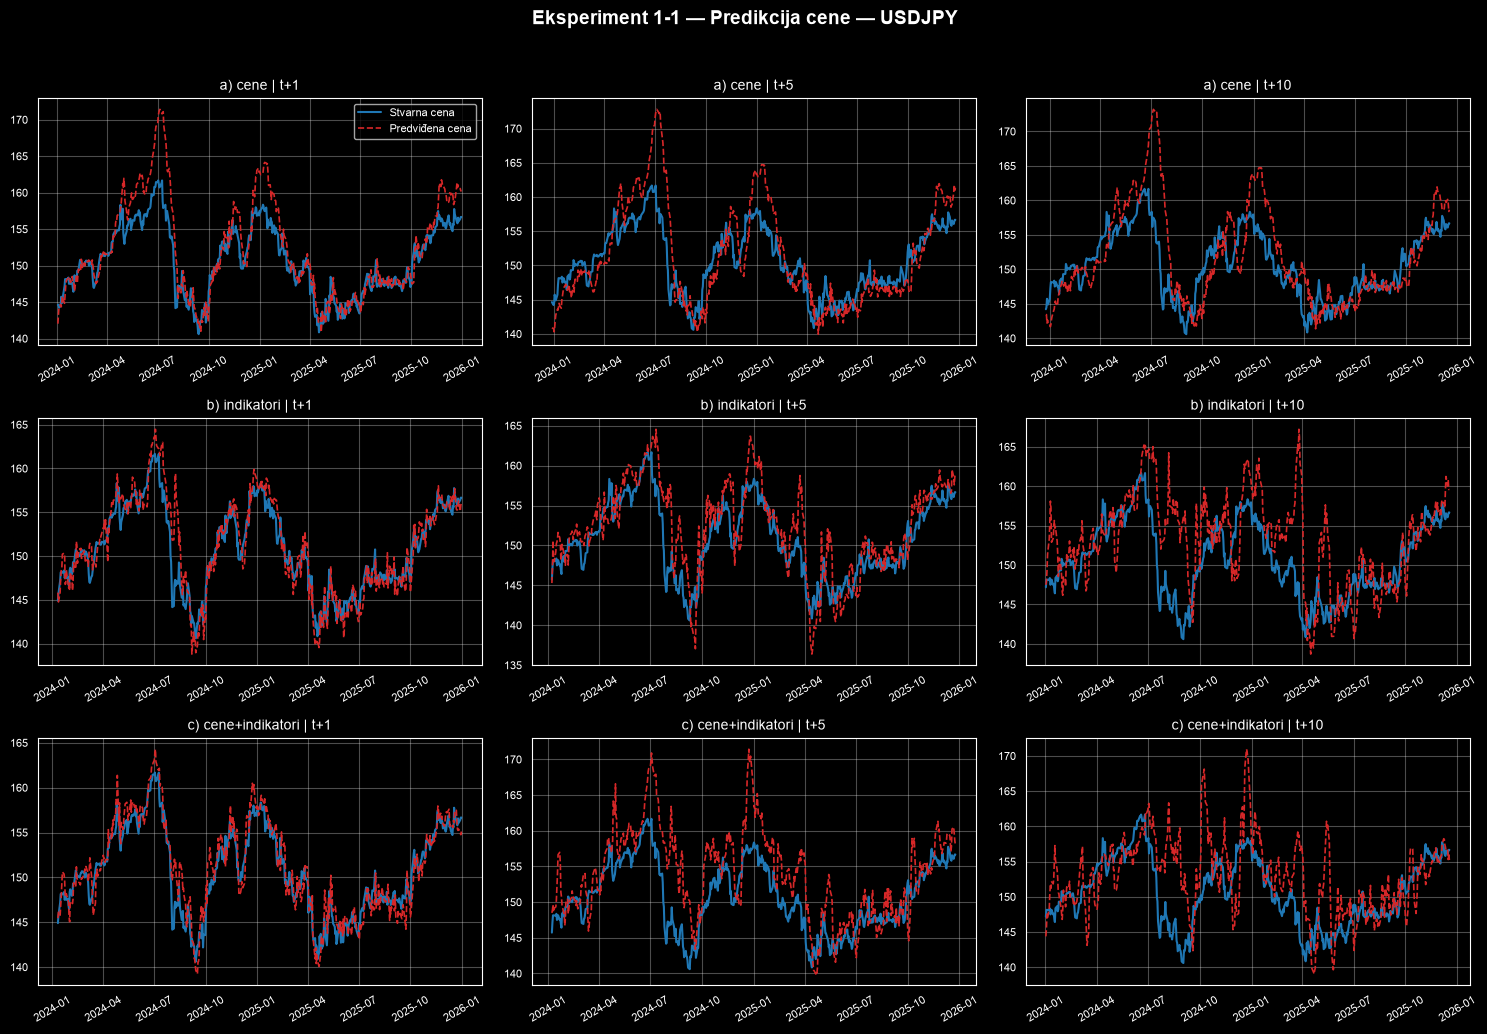

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

SUBCASES_1_1 = ['a) cene', 'b) indikatori', 'c) cene+indikatori']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_1_1), len(HORIZONS_1_1),
                              figsize=(5 * len(HORIZONS_1_1), 3.5 * len(SUBCASES_1_1)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 1-1 — Predikcija cene — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_1_1):
        for col, h in enumerate(HORIZONS_1_1):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_1_1:
                ax.set_title(f"{subcase} | t+{h} (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_1_1[key]
            dates_plot = data['dates']
            y_test = data['y_test']
            y_pred = data['y_pred']

            ax.plot(dates_plot, y_test, label='Stvarna cena', color='#1f77b4', linewidth=1.5)
            ax.plot(dates_plot, y_pred, label='Predviđena cena', color='#d62728', linewidth=1.2, linestyle='--')

            ax.set_title(f"{subcase} | t+{h}", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 🚀 FAZA 6: EKSPERIMENT 1-2
### + ROC od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)

In [11]:
HORIZONS_1_2 = [1, 3, 5, 10]
predictions_1_2 = {}  # {(pair, subcase, horizon): {"dates":..., "y_test":..., "y_pred":...}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)  # ROC od CENA

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)  # ROC od INDIKATORA

    targets = add_price_targets(pdf, HORIZONS_1_2)

    feature_sets = {
        'a) cene+ROC(cena)': (pd.concat([price_lags, roc_price], axis=1), 'standard'),
        'b) indikatori+ROC(ind)': (pd.concat([indicator_lags, roc_indicators], axis=1), 'robust'),
        'c) cene+ind+ROC(oba)': (pd.concat([price_lags, roc_price, indicator_lags, roc_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_2:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-2 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-2', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })

            predictions_1_2[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 1-2 završen.")

[1-2 c) cene+ind+ROC(oba) | USDJPY | t+10] MAE=9.28300 RMSE=12.11826 R2=-5.3927 | feat=58 iter=134 ✓konv.

✓ Eksperiment 1-2 završen.


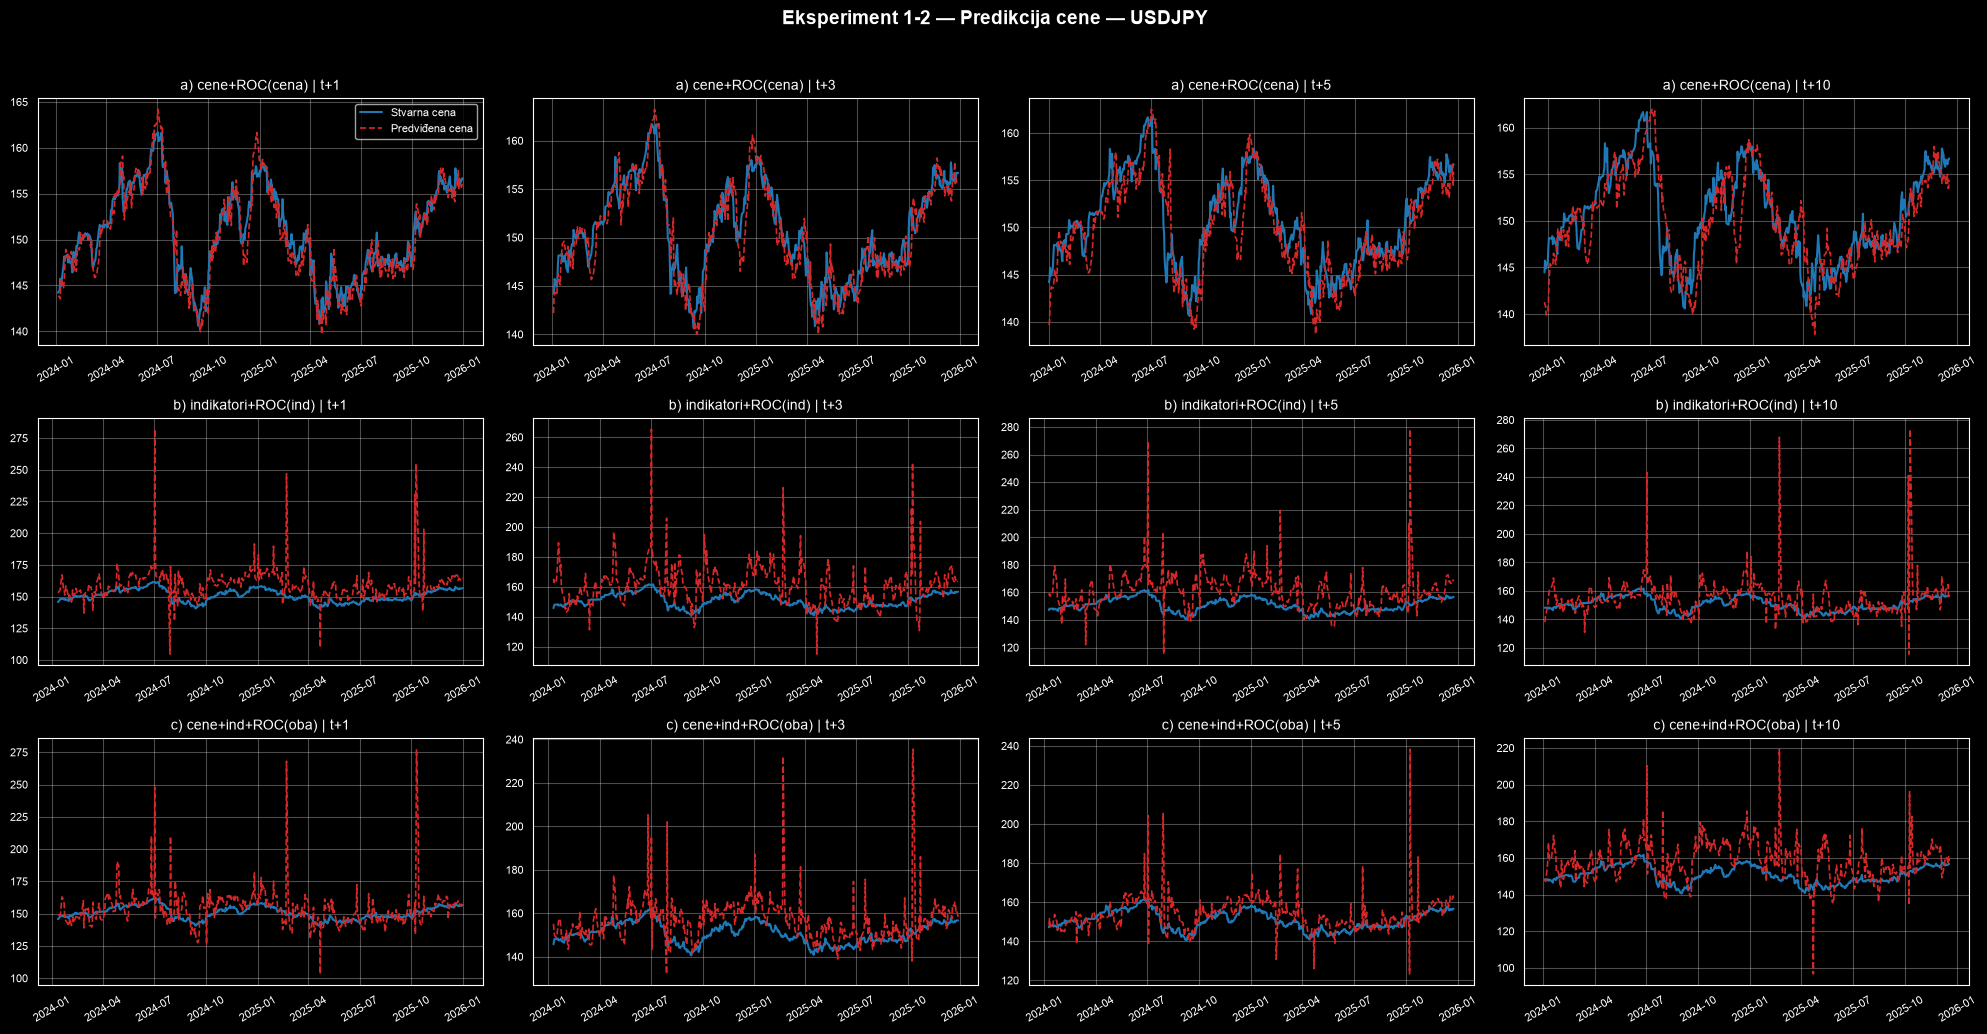

In [12]:
SUBCASES_1_2 = ['a) cene+ROC(cena)', 'b) indikatori+ROC(ind)', 'c) cene+ind+ROC(oba)']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_1_2), len(HORIZONS_1_2),
                              figsize=(5 * len(HORIZONS_1_2), 3.5 * len(SUBCASES_1_2)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 1-2 — Predikcija cene — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_1_2):
        for col, h in enumerate(HORIZONS_1_2):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_1_2:
                ax.set_title(f"{subcase} | t+{h} (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_1_2[key]
            dates_plot = data['dates']
            y_test = data['y_test']
            y_pred = data['y_pred']

            ax.plot(dates_plot, y_test, label='Stvarna cena', color='#1f77b4', linewidth=1.5)
            ax.plot(dates_plot, y_pred, label='Predviđena cena', color='#d62728', linewidth=1.2, linestyle='--')

            ax.set_title(f"{subcase} | t+{h}", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 🚀 FAZA 7: EKSPERIMENT 1-3
### + ROC i SMA od ulaznih varijabli → cena(t+1,t+3,t+5,t+10)

In [13]:
HORIZONS_1_3 = [1, 3, 5, 10]
predictions_1_3 = {}  # {(pair, subcase, horizon): {"dates":..., "y_test":..., "y_pred":...}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)
    sma_price = add_sma(pdf, ['Price'], 14)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)
    sma_indicators = add_sma(pdf, INDICATOR_COLS, 14)

    targets = add_price_targets(pdf, HORIZONS_1_3)

    feature_sets = {
        'a) cene+ROC+SMA(cena)': (pd.concat([price_lags, roc_price, sma_price], axis=1), 'standard'),
        'b) ind+ROC+SMA(ind)': (pd.concat([indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
        'c) sve kombinovano': (pd.concat([price_lags, roc_price, sma_price, indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_1_3:
            combo = pd.concat([X_df, targets[[f'Target_t+{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue
            X = combo[X_df.columns].values
            y = combo[f'Target_t+{h}'].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[1-3 {subcase} | {pair_name} | t+{h}] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} "
                  f"R2={metrics['R2']:.4f} | feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '1-3', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}', 'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc'], 'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'], 'Converged': metrics['converged'],
            })

            predictions_1_3[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 1-3 završen.")

[1-3 c) sve kombinovano | USDJPY | t+10] MAE=16.49623 RMSE=20.05869 R2=-16.5148 | feat=72 iter=144 ✓konv.

✓ Eksperiment 1-3 završen.


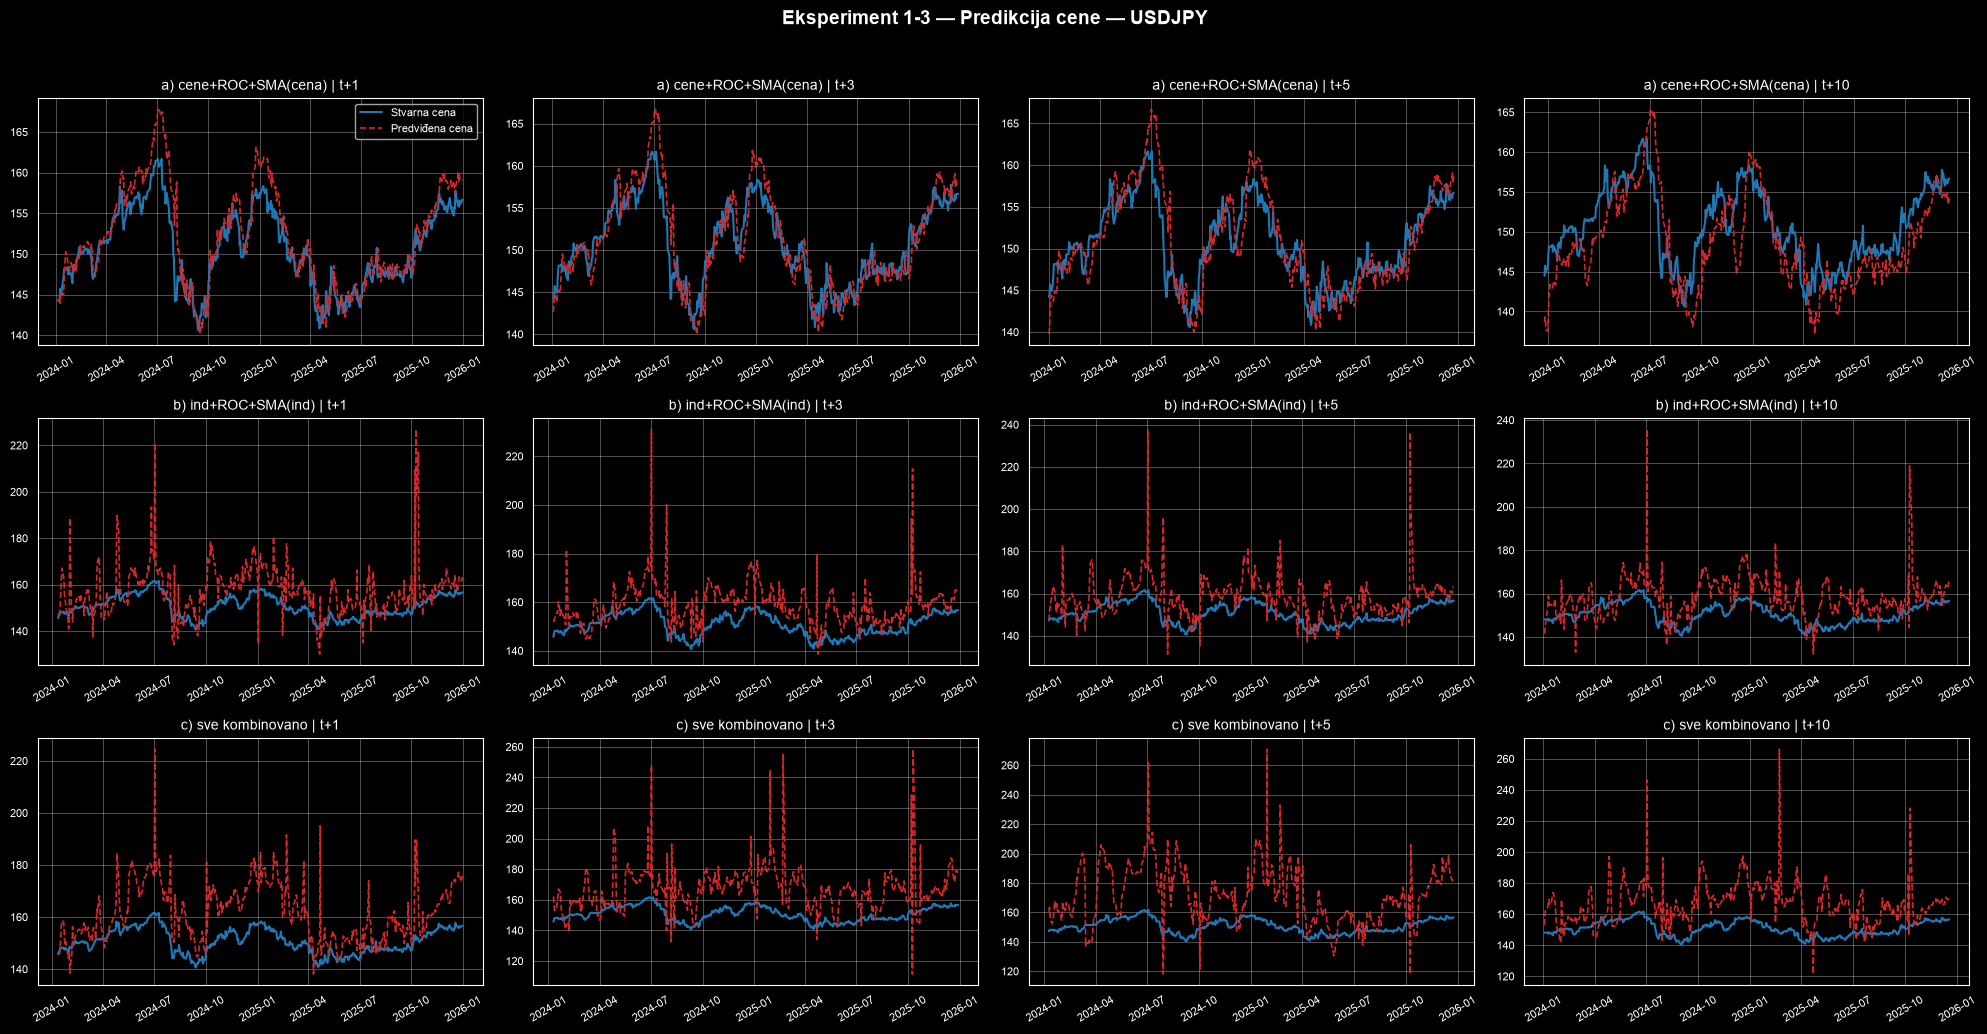

In [14]:
SUBCASES_1_3 = ['a) cene+ROC+SMA(cena)', 'b) ind+ROC+SMA(ind)', 'c) sve kombinovano']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_1_3), len(HORIZONS_1_3),
                              figsize=(5 * len(HORIZONS_1_3), 3.5 * len(SUBCASES_1_3)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 1-3 — Predikcija cene — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_1_3):
        for col, h in enumerate(HORIZONS_1_3):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_1_3:
                ax.set_title(f"{subcase} | t+{h} (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_1_3[key]
            dates_plot = data['dates']
            y_test = data['y_test']
            y_pred = data['y_pred']

            ax.plot(dates_plot, y_test, label='Stvarna cena', color='#1f77b4', linewidth=1.5)
            ax.plot(dates_plot, y_pred, label='Predviđena cena', color='#d62728', linewidth=1.2, linestyle='--')

            ax.set_title(f"{subcase} | t+{h}", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


In [15]:
HORIZONS_EXP2 = [1, 3, 5, 10]
results_exp2 = []

predictions_2_1 = {}
predictions_2_2 = {}
predictions_2_3 = {}

print("Pokretanje EKSPERIMENTA 2 (Predviđanje prinosa - Regresija)...\n")

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # --- PRIPREMA BAZNIH INPUTA ---
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)

    # --- PRIPREMA IZVEDENIH INPUTA (ROC i SMA sa prozorom 14) ---
    roc_price = add_roc(pdf, ['Price'], 14)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)

    sma_price = add_sma(pdf, ['Price'], 14)
    sma_indicators = add_sma(pdf, INDICATOR_COLS, 14)

    # --- GENERISANJE TARGETA (Budući prinosi) ---
    targets_exp2 = add_return_targets(pdf, HORIZONS_EXP2)

    # =========================================================================
    # EKSPERIMENT 2-1
    # =========================================================================
    feature_sets_2_1 = {
        'a) cene': (price_lags, 'standard'),
        'b) indikatori': (indicator_lags, 'robust'),
        'c) cene+indikatori': (pd.concat([price_lags, indicator_lags], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets_2_1.items():
        for h in HORIZONS_EXP2:
            combo = pd.concat([X_df, targets_exp2[[f'Target_ROC_{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50: continue
            X, y, dates_arr = combo[X_df.columns].values, combo[f'Target_ROC_{h}'].values, combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None: continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-1 {subcase:18s} | {pair_name} | ROC({h:2d})] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} R2={metrics['R2']:.4f} | feat={metrics['n_features']:3d} {conv_flag}")

            results_exp2.append({
                'Experiment': '2-1', 'Subcase': subcase, 'Pair': pair_name, 'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'], 'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc']
            })
            predictions_2_1[(pair_name, subcase, h)] = {'dates': metrics['test_dates'], 'y_test': metrics['y_test'], 'y_pred': metrics['y_pred']}

    # =========================================================================
    # EKSPERIMENT 2-2
    # =========================================================================
    feature_sets_2_2 = {
        'a) cene+ROC(cena)': (pd.concat([price_lags, roc_price], axis=1), 'standard'),
        'b) indikatori+ROC(ind)': (pd.concat([indicator_lags, roc_indicators], axis=1), 'robust'),
        'c) cene+ind+ROC(oba)': (pd.concat([price_lags, roc_price, indicator_lags, roc_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets_2_2.items():
        for h in HORIZONS_EXP2:
            combo = pd.concat([X_df, targets_exp2[[f'Target_ROC_{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50: continue
            X, y, dates_arr = combo[X_df.columns].values, combo[f'Target_ROC_{h}'].values, combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None: continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-2 {subcase:18s} | {pair_name} | ROC({h:2d})] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} R2={metrics['R2']:.4f} | feat={metrics['n_features']:3d} {conv_flag}")

            results_exp2.append({
                'Experiment': '2-2', 'Subcase': subcase, 'Pair': pair_name, 'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'], 'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc']
            })
            predictions_2_2[(pair_name, subcase, h)] = {'dates': metrics['test_dates'], 'y_test': metrics['y_test'], 'y_pred': metrics['y_pred']}

    # =========================================================================
    # EKSPERIMENT 2-3
    # =========================================================================
    feature_sets_2_3 = {
        'a) cene+ROC+SMA(cena)': (pd.concat([price_lags, roc_price, sma_price], axis=1), 'standard'),
        'b) indikatori+ROC+SMA(ind)': (pd.concat([indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
        'c) cene+ind+ROC+SMA(oba)': (pd.concat([price_lags, roc_price, sma_price, indicator_lags, roc_indicators, sma_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets_2_3.items():
        for h in HORIZONS_EXP2:
            combo = pd.concat([X_df, targets_exp2[[f'Target_ROC_{h}']], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50: continue
            X, y, dates_arr = combo[X_df.columns].values, combo[f'Target_ROC_{h}'].values, combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None: continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-3 {subcase:18s} | {pair_name} | ROC({h:2d})] MAE={metrics['MAE']:.5f} RMSE={metrics['RMSE']:.5f} R2={metrics['R2']:.4f} | feat={metrics['n_features']:3d} {conv_flag}")

            results_exp2.append({
                'Experiment': '2-3', 'Subcase': subcase, 'Pair': pair_name, 'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'], 'R2': metrics['R2'], 'MAPE': metrics['MAPE'], 'DirAcc': metrics['DirAcc']
            })
            predictions_2_3[(pair_name, subcase, h)] = {'dates': metrics['test_dates'], 'y_test': metrics['y_test'], 'y_pred': metrics['y_pred']}

    print(f"\n  ✓ Završena sva tri pod-eksperimenta za par: {pair_name}\n" + "-"*60)

print("\n✓ KOMPLETAN EKSPERIMENT 2 JE USPEŠNO ZAVRŠEN!")

[2-3 c) cene+ind+ROC+SMA(oba) | USDJPY | ROC(10)] MAE=1.76460 RMSE=2.30801 R2=-0.4870 | feat= 72 ✓konv.

  ✓ Završena sva tri pod-eksperimenta za par: USDJPY
------------------------------------------------------------

✓ KOMPLETAN EKSPERIMENT 2 JE USPEŠNO ZAVRŠEN!


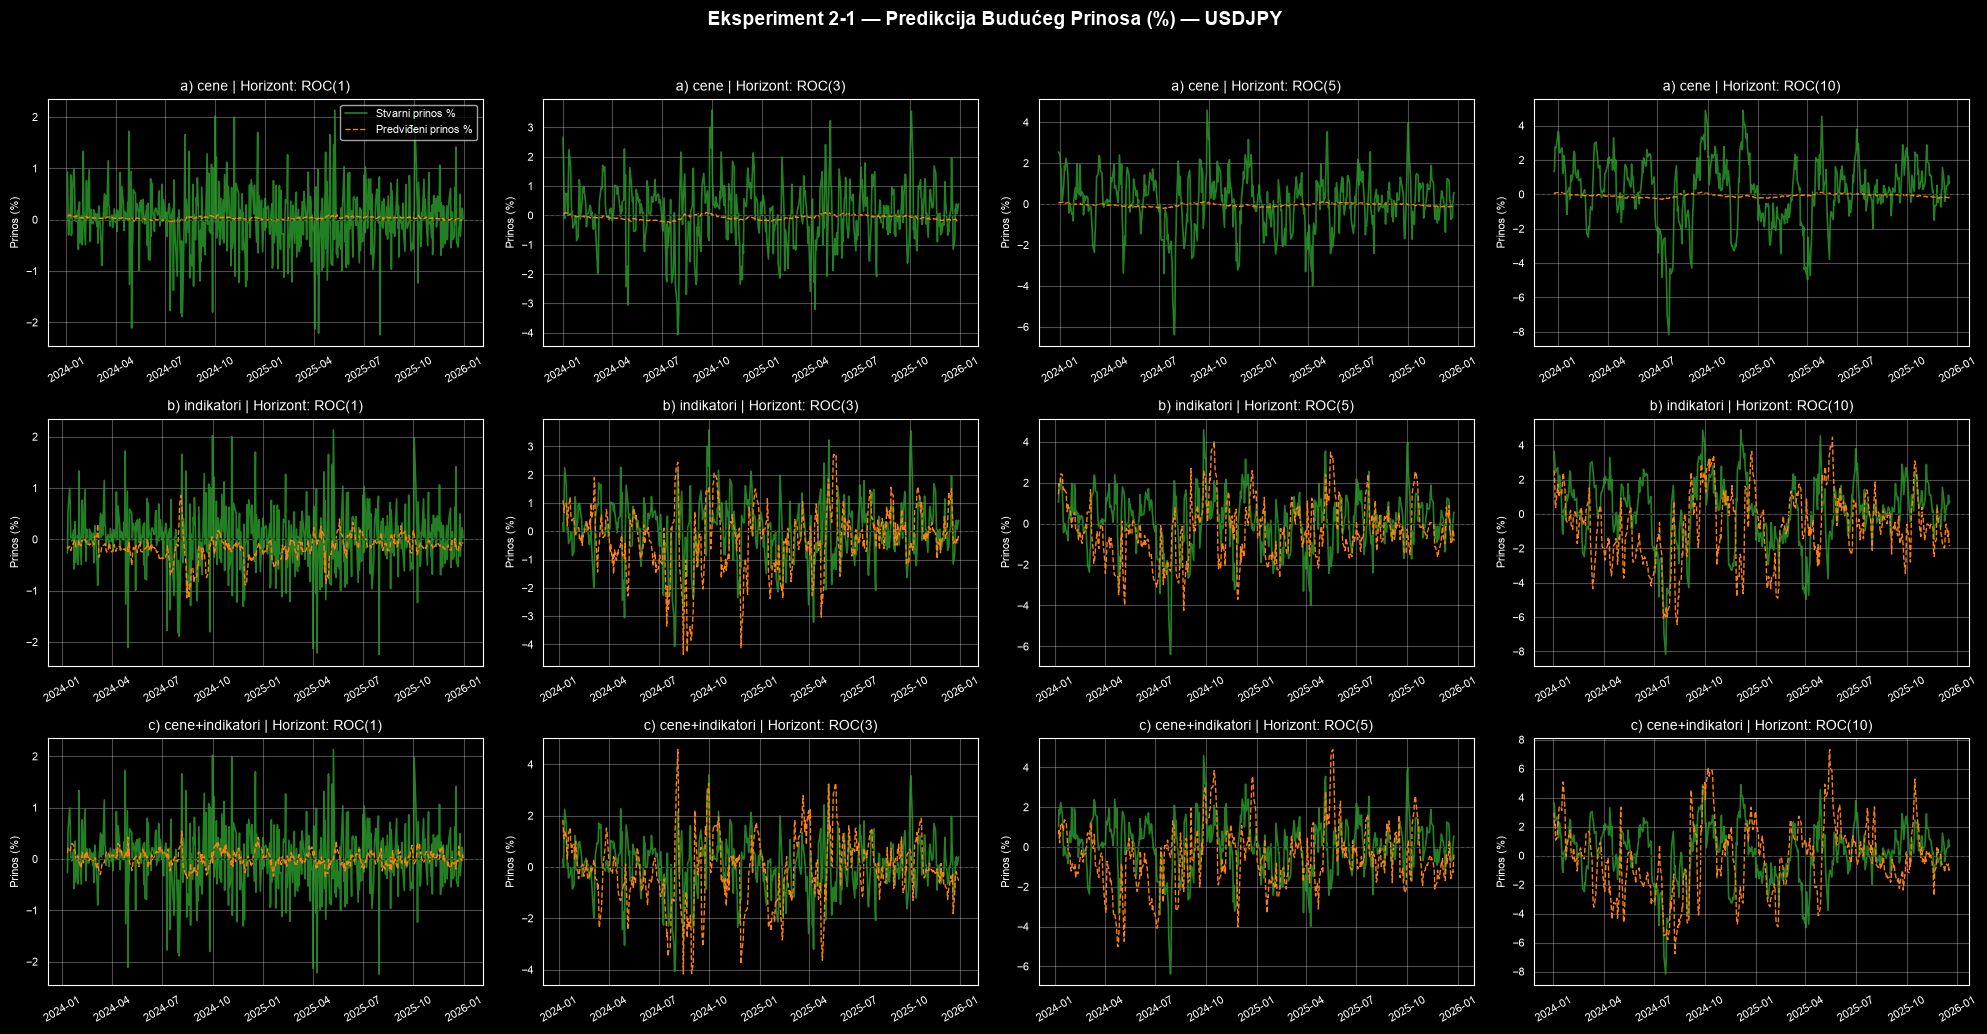

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Definisanje podslučajeva i horizonata za Eksperiment 2-1
SUBCASES_2_1 = ['a) cene', 'b) indikatori', 'c) cene+indikatori']
HORIZONS_EXP2 = [1, 3, 5, 10]

for pair_name in features['Pair'].unique():
    # Kreiramo grid grafika: 3 reda (a, b, c) x 4 kolone (horizonti 1, 3, 5, 10)
    fig, axes = plt.subplots(len(SUBCASES_2_1), len(HORIZONS_EXP2),
                             figsize=(5 * len(HORIZONS_EXP2), 3.5 * len(SUBCASES_2_1)),
                             squeeze=False)

    fig.suptitle(f"Eksperiment 2-1 — Predikcija Budućeg Prinosa (%) — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_2_1):
        for col, h in enumerate(HORIZONS_EXP2):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_2_1:
                ax.set_title(f"{subcase} | ROC({h}) (nema podataka)")
                ax.axis('off')
                continue

            # Izvlačenje istorijskih podataka iz testnog skupa
            data = predictions_2_1[key]
            dates_plot = data['dates']
            y_test = data['y_test']
            y_pred = data['y_pred']

            # Crtanje linija (Stvarni prinos vs Predviđeni prinos)
            ax.plot(dates_plot, y_test, label='Stvarni prinos %', color='#2ca02c', linewidth=1.2, alpha=0.8)
            ax.plot(dates_plot, y_pred, label='Predviđeni prinos %', color='#ff7f0e', linewidth=1.0, linestyle='--')

            # Horizontalna linija na 0% radi lakše orijentacije (da li je prinos pozitivan ili negativan)
            ax.axhline(0, color='black', linestyle=':', alpha=0.5)

            ax.set_title(f"{subcase} | Horizont: ROC({h})", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.set_ylabel("Prinos (%)", fontsize=8)
            ax.grid(alpha=0.3)

            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def get_direction_labels(returns_array):
    """Binarizuje prinose: 1 ako je prinos pozitivan (UP), 0 ako je negativan ili nula (DOWN)."""
    return np.where(returns_array > 0, 1, 0)

def plot_exp2_confusion_matrix(cm, ax, title):
    """Pomoćna funkcija za vizuelni prikaz matrice (slično vašoj plot_confusion_matrix)."""
    labels = ['DOWN', 'UP']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 10})
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.set_xlabel('Predviđeno', fontsize=8)
    ax.set_ylabel('Stvarno', fontsize=8)

# Liste za strukturu grida
SUBCASES_2_1 = ['a) cene', 'b) indikatori', 'c) cene+indikatori']
HORIZONS_EXP2 = [1, 3, 5, 10]
cm_results_exp2 = []

print("Generisanje Confusion Matrix grida za Eksperiment 2-1 (Smer prinosa)...\n")

for pair_name in features['Pair'].unique():
    # Kreiramo grid: 3 reda (a, b, c) x 4 kolone (horizonti)
    fig, axes = plt.subplots(len(SUBCASES_2_1), len(HORIZONS_EXP2),
                             figsize=(4.5 * len(HORIZONS_EXP2), 4 * len(SUBCASES_2_1)),
                             squeeze=False)
    fig.suptitle(f"Confusion Matrix — Smer Budućeg Prinosa — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_2_1):
        for col, h in enumerate(HORIZONS_EXP2):
            ax = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_2_1:
                ax.set_title(f"{subcase} | ROC({h})\n(Nema podataka)")
                ax.axis('off')
                continue

            data = predictions_2_1[key]
            y_test = data['y_test']
            y_pred = data['y_pred']

            # Pretvaranje kontinualnih prinosa u binarne smerove (UP=1, DOWN=0)
            true_dir = get_direction_labels(y_test)
            pred_dir = get_direction_labels(y_pred)

            # Računanje matrice konfuzije
            cm = confusion_matrix(true_dir, pred_dir, labels=[0, 1])

            # Ekstrakcija TN, FP, FN, TP
            tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
            total = cm.sum()

            # Računanje klasifikacionih metrika
            acc = (tp + tn) / total * 100 if total > 0 else 0
            precision = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0
            f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

            # Čuvanje rezultata za tabelu
            cm_results_exp2.append({
                'Pair': pair_name, 'Experiment': '2-1', 'Subcase': subcase, 'Horizon': f'ROC({h})',
                'Accuracy_%': acc, 'Precision_%': precision, 'Recall_%': recall, 'F1_Score_%': f1,
                'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
            })

            # Iscrtavanje pojedinačne matrice na gridu
            title_text = f"{subcase} | ROC({h})\nAcc={acc:.1f}% | F1={f1:.1f}%"
            plot_exp2_confusion_matrix(cm, ax, title_text)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Pretvaranje u DataFrame i čuvanje u Excel
df_cm_exp2 = pd.DataFrame(cm_results_exp2)
output_cm_excel_path = 'Experiment2_ConfusionMatrix.xlsx'
df_cm_exp2.to_excel(output_cm_excel_path, index=False)

print("\n" + "="*80)
print(f"✓ MATRICE KONFUZIJE SU USPEŠNO GENERISANE I PRIKAZANE!")
print(f"✓ Rezultati klasifikacije smera su sačuvani u: '{output_cm_excel_path}'")
print("="*80)


✓ MATRICE KONFUZIJE SU USPEŠNO GENERISANE I PRIKAZANE!
✓ Rezultati klasifikacije smera su sačuvani u: 'Experiment2_ConfusionMatrix.xlsx'


In [17]:
# Pretvaranje rezultata u DataFrame
df_results_exp2 = pd.DataFrame(results_exp2)

# Prikaz prvih nekoliko redova rezultata unutar notebooka
print("\n" + "="*80 + "\nPREGLED REZULTATA EKSPERIMENTA 2 (PRVIH 10 REDOVA):\n" + "="*80)
print(df_results_exp2.head(10).to_string(index=False))

# Čuvanje rezultata u novi Excel fajl
output_excel_path = 'Experiment2_Returns_Results.xlsx'
df_results_exp2.to_excel(output_excel_path, index=False)
print(f"\n✓ Svi rezultati Eksperimenta 2 su uspešno eksportovani u fajl: '{output_excel_path}'")


PREGLED REZULTATA EKSPERIMENTA 2 (PRVIH 10 REDOVA):
Experiment            Subcase   Pair Horizon      MAE     RMSE        R2       MAPE    DirAcc
       2-1            a) cene EURUSD  ROC(1) 0.319514 0.435283 -0.004408 102.577457 53.269231
       2-1            a) cene EURUSD  ROC(3) 0.552692 0.745838 -0.008109 114.347526 54.615385
       2-1            a) cene EURUSD  ROC(5) 0.708271 0.944131 -0.020035 158.903516 55.105973
       2-1            a) cene EURUSD ROC(10) 1.013548 1.320450  0.004865 132.415054 50.193050
       2-1      b) indikatori EURUSD  ROC(1) 0.352516 0.472455 -0.171981 177.900470 49.610895
       2-1      b) indikatori EURUSD  ROC(3) 0.969273 1.333557 -2.197654 457.625723 56.614786
       2-1      b) indikatori EURUSD  ROC(5) 1.192085 1.482974 -1.498390 516.431543 54.580897
       2-1      b) indikatori EURUSD ROC(10) 1.704440 2.061621 -1.414565 458.867128 58.984375
       2-1 c) cene+indikatori EURUSD  ROC(1) 0.328753 0.442991 -0.030362 124.004781 50.194553
       

## 📊 FAZA 8: Zbirni rezultati svih eksperimenata (1-1, 1-2, 1-3)

In [18]:
results_df = pd.DataFrame(results_all)
results_df = results_df[['Experiment', 'Subcase', 'Pair', 'Horizon',
                          'MAE', 'RMSE', 'R2', 'MAPE', 'DirAcc',
                          'Train_Size', 'Test_Size', 'N_Features', 'N_Iter', 'Converged']]

print("="*100)
print(f"SVI REZULTATI — {len(results_df)} kombinacija (eksperiment × podslučaj × par × horizont)")
print("="*100 + "\n")
print(results_df.to_string(index=False))

n_not_converged = (~results_df['Converged']).sum()
if n_not_converged > 0:
    print(f"\n⚠ Upozorenje: {n_not_converged} model(a) NIJE konvergiralo (zaglavilo na max_iter={MLP_PARAMS['max_iter']}).")
    print("   Razmotri dalje povećanje max_iter za te kombinacije ako su im rezultati bitni.")

results_df.to_excel('Experiment1_Results.xlsx', index=False)
print(f"\n✓ Zbirna tabela sačuvana u: Experiment1_Results.xlsx")

SVI REZULTATI — 198 kombinacija (eksperiment × podslučaj × par × horizont)

Experiment                Subcase   Pair Horizon       MAE      RMSE          R2      MAPE    DirAcc  Train_Size  Test_Size  N_Features  N_Iter  Converged
       1-1                a) cene EURUSD     t+1  0.005392  0.007205    0.973513  0.486834 48.461538        2083        521           5     220       True
       1-1                a) cene EURUSD     t+5  0.009120  0.011850    0.928473  0.825818 49.710983        2080        520           5     267       True
       1-1                a) cene EURUSD    t+10  0.012330  0.015864    0.872042  1.117559 44.015444        2076        519           5     143       True
       1-1          b) indikatori EURUSD     t+1  0.009243  0.012345    0.923077  0.837450 48.832685        2059        515          39     637       True
       1-1          b) indikatori EURUSD     t+5  0.014560  0.020167    0.795086  1.317969 47.563353        2056        514          39     661      

## 🗂️ FAZA 9: Confusion Matrix — Predikcija smera kretanja




## 💾 Čuvanje pratećih fajlova

In [19]:
from sklearn.metrics import confusion_matrix, classification_report
import itertools

def direction_labels(y_arr):
    """Pretvori niz cena u binarne oznake smera: 1=rast, 0=pad (u odnosu na prethodni)."""
    deltas = np.diff(y_arr)
    return (deltas > 0).astype(int)

def plot_confusion_matrix(cm, ax, title, classes=["DOWN","UP"]):
    """Prikaži normalizedovanu confusion matrix na datoj osi."""
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title, fontsize=8, pad=4)
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(classes, fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_ylabel('Stvarno', fontsize=7)
    ax.set_xlabel('Predviđeno', fontsize=7)
    for i, j in itertools.product(range(2), range(2)):
        ax.text(j, i, f"{cm[i,j]}\n({cm_norm[i,j]:.0%})",
                ha='center', va='center', fontsize=8,
                color='white' if cm_norm[i,j] > 0.5 else 'black')

# Skupi SVE predikcije iz sva 3 eksperimenta u jedan dict
all_predictions = {}
for key, val in predictions_1_1.items():
    pair, sub, h = key
    all_predictions[('1-1', pair, sub, h)] = val
for key, val in predictions_1_2.items():
    pair, sub, h = key
    all_predictions[('1-2', pair, sub, h)] = val
for key, val in predictions_1_3.items():
    pair, sub, h = key
    all_predictions[('1-3', pair, sub, h)] = val

# ── Tabelarni prikaz confusion matrix metrika ────────────────────────────────
cm_records = []
for (exp, pair, sub, h), data in all_predictions.items():
    yt = data['y_test']
    yp = data['y_pred']
    if len(yt) < 3:
        continue

    true_dir  = direction_labels(yt)
    pred_dir  = direction_labels(yp)
    min_len   = min(len(true_dir), len(pred_dir))
    true_dir, pred_dir = true_dir[:min_len], pred_dir[:min_len]

    if min_len < 5:
        continue

    cm = confusion_matrix(true_dir, pred_dir, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    acc  = (tp + tn) / (tp + tn + fp + fn + 1e-9) * 100
    prec = tp / (tp + fp + 1e-9) * 100
    rec  = tp / (tp + fn + 1e-9) * 100
    f1   = 2 * prec * rec / (prec + rec + 1e-9)

    cm_records.append({
        'Experiment': exp, 'Subcase': sub, 'Pair': pair, 'Horizon': h,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'Accuracy_%': round(acc, 1), 'Precision_%': round(prec, 1),
        'Recall_%': round(rec, 1), 'F1_%': round(f1, 1),
    })

cm_df = pd.DataFrame(cm_records)
print("="*110)
print(f"CONFUSION MATRIX METRIKE — {len(cm_df)} kombinacija")
print("="*110)
print(cm_df.to_string(index=False))

# Sačuvaj u Excel
cm_df.to_excel('Experiment1_ConfusionMatrix.xlsx', index=False)
print("\n✓ Sačuvano: Experiment1_ConfusionMatrix.xlsx")


CONFUSION MATRIX METRIKE — 198 kombinacija
Experiment                Subcase   Pair  Horizon  TP  TN  FP  FN  Accuracy_%  Precision_%  Recall_%  F1_%
       1-1                a) cene EURUSD        1 124 135 135 126        49.8         47.9      49.6  48.7
       1-1                a) cene EURUSD        5 125 139 130 125        50.9         49.0      50.0  49.5
       1-1                a) cene EURUSD       10 116 116 153 133        44.8         43.1      46.6  44.8
       1-1          b) indikatori EURUSD        1 121 136 130 127        50.0         48.2      48.8  48.5
       1-1          b) indikatori EURUSD        5 120 129 136 128        48.5         46.9      48.4  47.6
       1-1          b) indikatori EURUSD       10 134 138 126 114        53.1         51.5      54.0  52.8
       1-1     c) cene+indikatori EURUSD        1 124 126 140 124        48.6         47.0      50.0  48.4
       1-1     c) cene+indikatori EURUSD        5 124 133 132 124        50.1         48.4      50.0 

### 📊 Vizuelni prikaz Confusion Matrica — po paru i horizontu (eksperiment 1-1, podslučaj c)


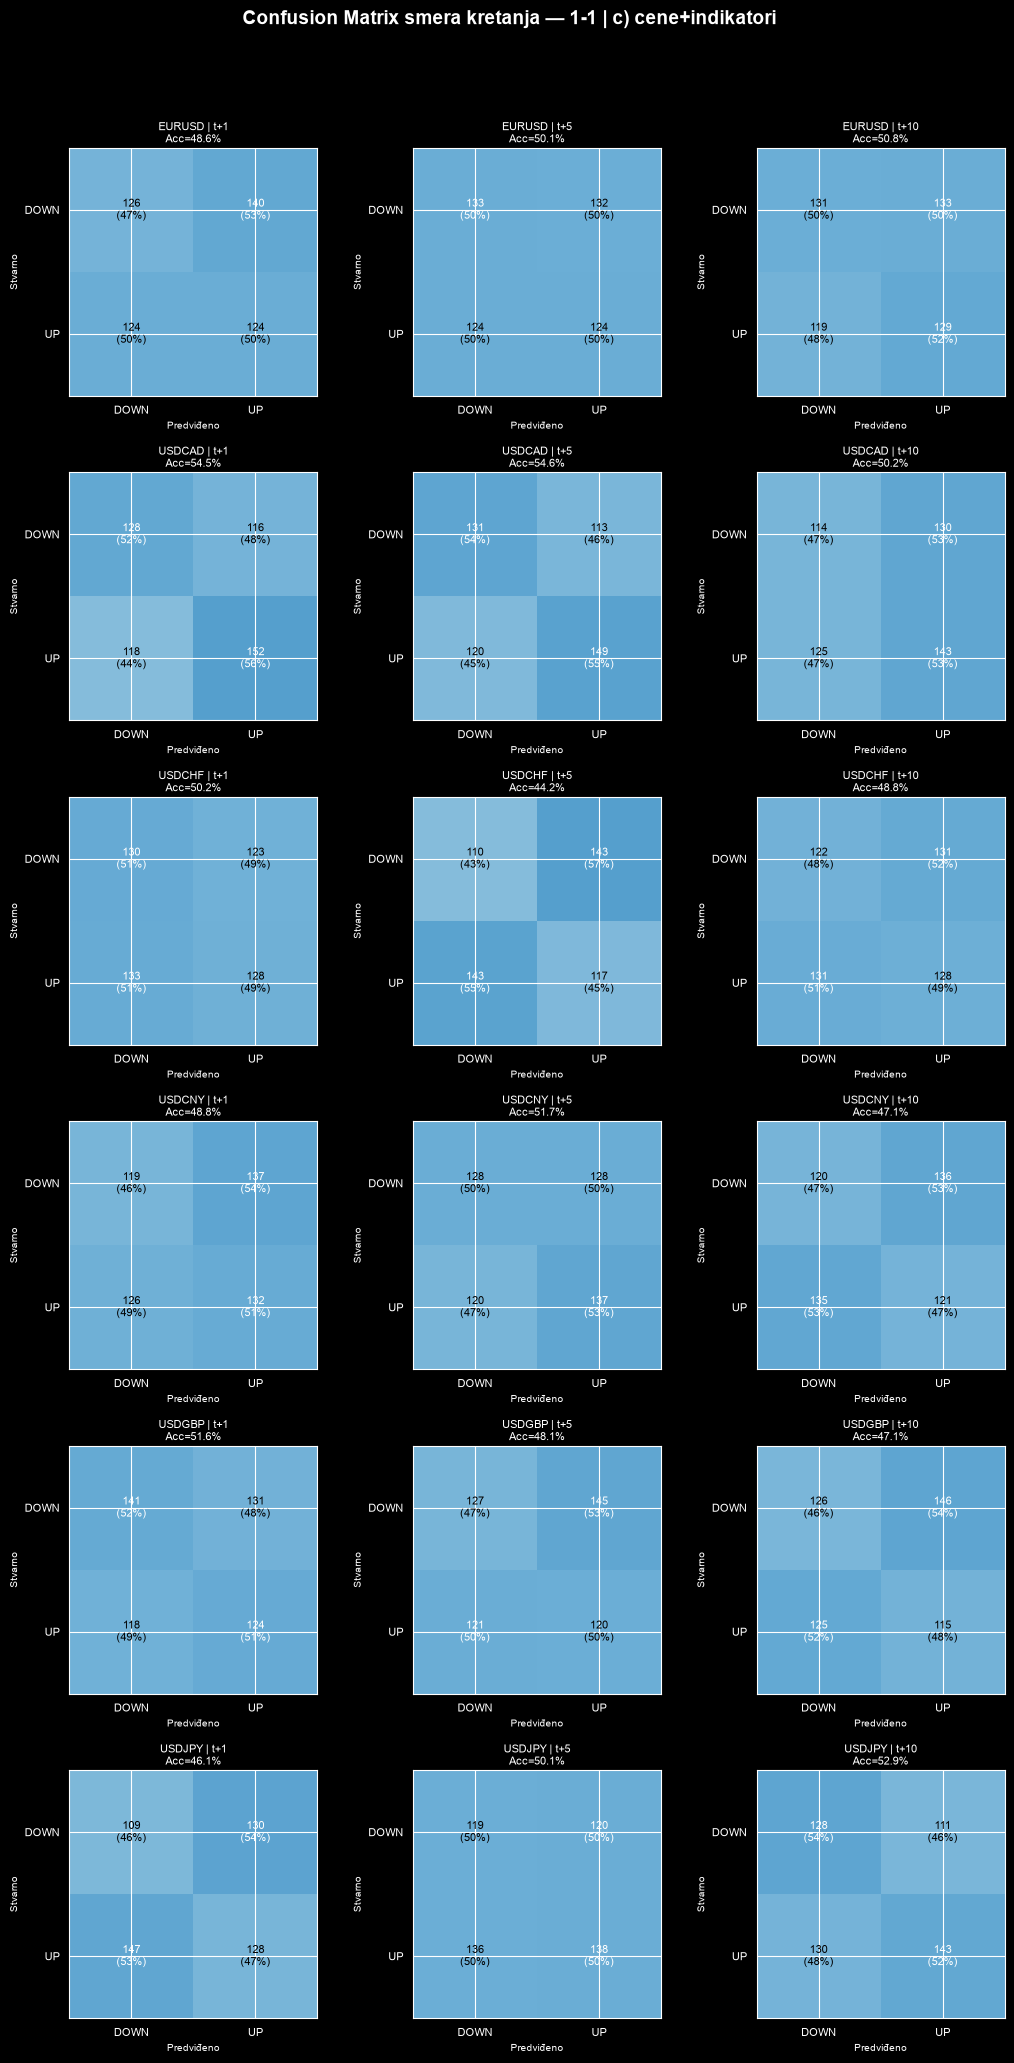

In [20]:
# Vizuelni grid: jedan red po paru, jedna kolona po horizontu
# Prikazujemo podslučaj "c" iz eksperimenta 1-1 kao reprezentativan primer

TARGET_EXP = '1-1'
TARGET_SUB = 'c) cene+indikatori'  # najkompletniji feature set

pairs    = sorted(set(k[1] for k in all_predictions if k[0]==TARGET_EXP and k[2]==TARGET_SUB))
horizons = sorted(set(k[3] for k in all_predictions if k[0]==TARGET_EXP and k[2]==TARGET_SUB))

if not pairs or not horizons:
    print("Nema podataka za prikaz.")
else:
    fig, axes = plt.subplots(len(pairs), len(horizons),
                              figsize=(3.5 * len(horizons), 3.5 * len(pairs)),
                              squeeze=False)
    fig.suptitle(f"Confusion Matrix smera kretanja — {TARGET_EXP} | {TARGET_SUB}",
                 fontsize=14, fontweight='bold')

    for ri, pair in enumerate(pairs):
        for ci, h in enumerate(horizons):
            ax = axes[ri][ci]
            key = (TARGET_EXP, pair, TARGET_SUB, h)

            if key not in all_predictions:
                ax.set_visible(False)
                continue

            data = all_predictions[key]
            yt, yp = data['y_test'], data['y_pred']

            true_dir = direction_labels(yt)
            pred_dir = direction_labels(yp)
            n = min(len(true_dir), len(pred_dir))
            true_dir, pred_dir = true_dir[:n], pred_dir[:n]

            cm = confusion_matrix(true_dir, pred_dir, labels=[0,1])
            acc = (cm[0,0]+cm[1,1]) / cm.sum() * 100
            plot_confusion_matrix(cm, ax, f"{pair} | t+{h}\nAcc={acc:.1f}%")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


In [21]:
missing_df.to_excel('00_Missing_Values_Report.xlsx', index=False)
currency_all.to_csv('01_Currency_Data_ALL.csv', index=False)
features.to_csv('02_Features_With_Indicators.csv', index=False)

print("✓ Sačuvani fajlovi:")
print("  - 00_Missing_Values_Report.xlsx")
print("  - 01_Currency_Data_ALL.csv")
print("  - 02_Features_With_Indicators.csv")
print("  - Experiment1_Results.xlsx  (svi rezultati 1-1, 1-2, 1-3)")

✓ Sačuvani fajlovi:
  - 00_Missing_Values_Report.xlsx
  - 01_Currency_Data_ALL.csv
  - 02_Features_With_Indicators.csv
  - Experiment1_Results.xlsx  (svi rezultati 1-1, 1-2, 1-3)
